Полезные ссылки
Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-sozdanie-tenzorov-konvertirovanie-v-numpy

Телеграм-канал: https://t.me/machine_learning_selfedu

PyTorch: https://pytorch.org/tutorials/

| №  | Пример кода                                                          | Что получится (`repr`)               | Размерность | Связь с источником          | Inplace-версия или примечание                   |
| -- | -------------------------------------------------------------------- | ------------------------------------ | ----------- | --------------------------- | ----------------------------------------------- |
| 1  | `torch.tensor([1, 2, 3], dtype=torch.float32)`                       | `tensor([1., 2., 3.])`               | `(3,)`      | Нет связи                   | Можно `tensor.fill_(0)`                         |
| 2  | `torch.empty(2, 3)`                                                  | Неинициализированные значения, мусор | `(2, 3)`    | Нет                         | После создания можно `tensor.fill_(5)`          |
| 3  | `torch.from_numpy(np.array([1,2,3]))`                                | `tensor([1, 2, 3])`                  | `(3,)`      | Есть — общая память с NumPy | Любое `inplace` на тензоре отразится на массиве |
| 4  | `torch.ones(2, 3)`                                                   | Матрица из единиц                    | `(2, 3)`    | Нет                         | `tensor.zero_()` — inplace                      |
| 5  | `torch.zeros(2, 3)`                                                  | Матрица из нулей                     | `(2, 3)`    | Нет                         | `tensor.fill_(1)`                               |
| 6  | `torch.eye(3)`                                                       | Единичная матрица                    | `(3, 3)`    | Нет                         | Можно `tensor.fill_diagonal_(2)`                |
| 7  | `torch.full((2, 3), 7)`                                              | Матрица, заполненная 7               | `(2, 3)`    | Нет                         | Можно `tensor.fill_(0)`                         |
| 8  | `torch.arange(0, 5)`                                                 | `tensor([0, 1, 2, 3, 4])`            | `(5,)`      | Нет                         | `tensor.add_(1)` — inplace                      |
| 9  | `torch.rand(2, 3)`                                                   | Случайные числа \~ U\[0,1)           | `(2, 3)`    | Нет                         | `tensor.uniform_(0, 2)`                         |
| 10 | `torch.randn(2, 3)`                                                  | Случайные числа \~ N(0,1)            | `(2, 3)`    | Нет                         | `tensor.normal_(2, 0.5)`                        |
| 11 | `torch.randint(0, 10, (2, 3))`                                       | Случайные целые от 0 до 9            | `(2, 3)`    | Нет                         | `tensor.random_(5, 15)`                         |
| 12 | `torch.normal(mean=0, std=1, size=(2, 3))`                           | Случайные числа \~ N(0,1)            | `(2, 3)`    | Нет                         | То же самое, `tensor.normal_()`                 |
| 13 | *(после создания)* `tensor = torch.empty(2, 2)`<br>`tensor.fill_(9)` | Матрица, заполненная 9               | `(2, 2)`    | Нет                         | Пример именно “создан пустым — заполнен”        |


In [2]:
import torch
import numpy as np

t = torch.Tensor(3, 5, 2)

# аналогично, и более приветствуется
t = torch.empty(3, 5, 2)
t

tensor([[[1.2766e+38, 1.8399e-42],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00]],

        [[0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00]],

        [[0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00],
         [0.0000e+00, 0.0000e+00]]])

In [6]:
# по умолчанию тип данных float32
t.dtype

torch.float32

In [7]:
t = torch.empty(3, 5, 2, dtype=torch.int32)

Вообще доступны следующие типы данных

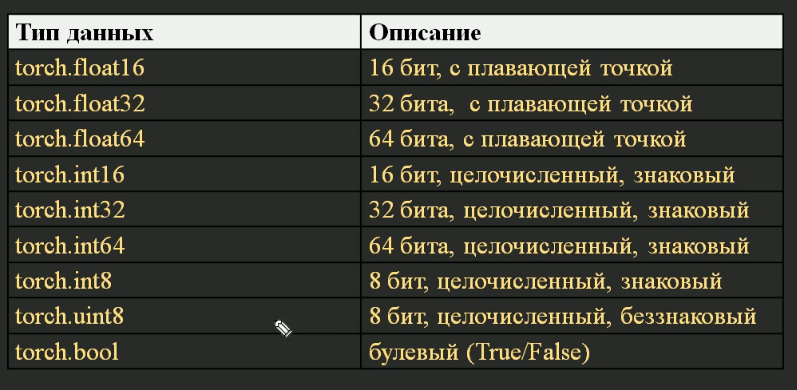

Раньше тензоры создавались при помощи разных классов

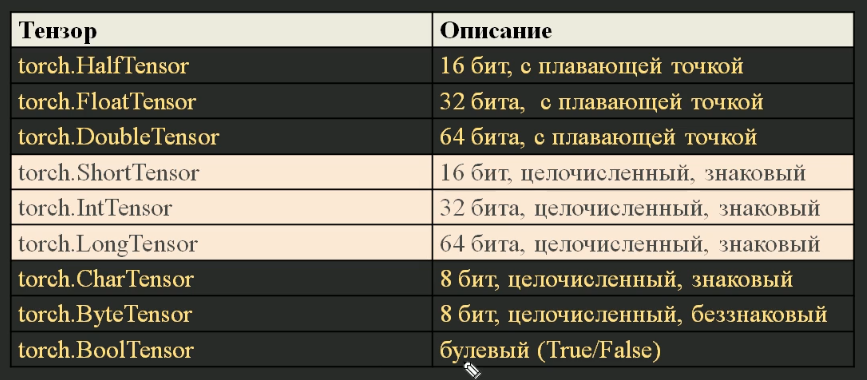

если требуется создать конкретный тензор:

In [11]:
t = torch.tensor([[1,2,3], [4,5,6]], dtype=torch.float32)
t

tensor([[1., 2., 3.],
        [4., 5., 6.]])

In [13]:
# число осей
t.dim()

2

In [15]:
# кол-во элементов по осям
print(t.size())
print(t.shape)

torch.Size([2, 3])
torch.Size([2, 3])


Часто требуется переносить даныне из numpy и обратно

In [35]:
dnp = np.array([[1,2], [3,4], [5,6]])
dnp

array([[1, 2],
       [3, 4],
       [5, 6]])

In [36]:
t1 = torch.from_numpy(dnp)
# переменные зависимы дрг от друга, если поменять dnp, поменяется и tnp
t1

tensor([[1, 2],
        [3, 4],
        [5, 6]], dtype=torch.int32)

In [37]:
# так можно не только передать массив, но и поменять тип его содержимого. Данные копируются
t2 = torch.tensor(dnp, dtype=torch.float32)
t2

tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])

In [38]:
dnp[0, 0] = 444
dnp

array([[444,   2],
       [  3,   4],
       [  5,   6]])

In [39]:
t1

tensor([[444,   2],
        [  3,   4],
        [  5,   6]], dtype=torch.int32)

In [40]:
t2

tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])

Обратно перевести тензор в numpy можно так:

In [41]:
t2np = t1.numpy()
t2np

array([[444,   2],
       [  3,   4],
       [  5,   6]])

Чтобы новая переменная была независима, делаем копи

In [42]:
t2np = t1.numpy().copy()
t2np

array([[444,   2],
       [  3,   4],
       [  5,   6]])

Можно преобразовать имеющийся тензор к нужному типу данных

half()  
float()  
double()  
short()  
int()  
long()  
char()  
byte()  
bool()  

In [45]:
t1.float().dtype

torch.float32

tensor([ 7., 30., 24.])